In [7]:
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import health_utils

importlib.reload(health_utils)
from health_utils import (
    HealthAnalyzer,
    disease_prevalence_by_sex,
    fit_bp_linear_regression,
    load_health_data,
    plot_bp_by_smoker,
    plot_bp_regression,
    plot_extended_analysis,
    plot_pca_scatter,
    run_pca_analysis,
    simulate_disease,
    test_smoking_bp,
    vector_matrix_bp_summary,
)

np.random.seed(42)
df = load_health_data("health_study_dataset.csv")

I den här cellen kör jag en simulering av sjukdomsandelen och ett t-test för att jämföra det systoliska blodtrycket mellan rökare och icke-rökare.

Simulering: för att se hur sannolikheten för sjukdom beter sig vid upprepade simuleringar jämfört med den faktiska andelen i datan.
T-test: för att testa om skillnaden i genomsnittligt blodtryck mellan rökare och icke-rökare är statistiskt säkerställd eller kan bero på slumpen.

In [8]:
real_p, sim_p = simulate_disease(df, n_sim=1000, seed=42)
print(f"Verklig sjukdomsandel: {real_p:.3f} | Simulerad andel: {sim_p:.3f}")

diff_bp, t_val, p_val = test_smoking_bp(df)
print(f"Skillnad i medel-BP (rökare - icke-rökare): {diff_bp:.2f} mmHg | t = {t_val:.2f}, p = {p_val:.4f}")

Verklig sjukdomsandel: 0.059 | Simulerad andel: 0.054
Skillnad i medel-BP (rökare - icke-rökare): 0.47 mmHg | t = 0.45, p = 0.6527


Jag laddar hälsodatan i HealthAnalyzer, skriver ut en grundläggande sammanfattning, räknar ut 95 % konfidensintervall för blodtrycket och ritar ett diagram över kolesterol per sjukdomsstatus. Så det ger en snabb överblick över datan, konfidensintervallet visar hur säkert medelvärdet för blodtrycket är och diagrammet gör det lätt att jämföra kolesterol mellan grupperna.
Det visar grundvärdena i studien, det troliga intervallet för medelblodtrycket och om kolesterolet ser högre ut vid sjukdom.

              Medel    Std    Min     Max
age           49.43  14.50   18.0   90.00
weight        73.41  13.69   33.7  114.40
height       171.85   9.80  144.4  200.40
systolic_bp  149.18  12.79  106.8  185.90
cholesterol    4.93   0.85    2.5    7.88

Blodtryck (medel): 149.18 mmHg | 95% KI: (148.29, 150.07)


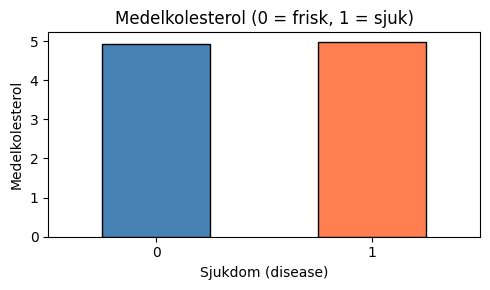

In [9]:
analyzer = HealthAnalyzer(Path("health_study_dataset.csv"))

print(analyzer.basic_summary())

mean_bp, low_bp, high_bp = analyzer.bp_ci_95()
print(f"\nBlodtryck (medel): {mean_bp:.2f} mmHg | 95% KI: ({low_bp:.2f}, {high_bp:.2f})")

analyzer.plot_cholesterol_by_disease()

I den här cellen analyserar jag blodtryck och mönster i datan med linjär algebra.
Vektorer och matriser ger en snabb överblick över blodtrycket med `numpy`.
Linjär regression visar undersöker hur ålder och vikt hänger ihop med blodtrycket, och ritar en graf för ålder.
PCA förenklar datan till två komponenter och ritar ett diagram per sjukdomsstatus för att hitta mönster.
Det gör jag för att se hur ålder och vikt påverkar blodtrycket samt om det finns tydliga mönster eller grupper i datan.

Vektor- och matrisanalys:
  dot_age_bp: 5988732.7000
  norm_age: 1456.8387
  norm_bp: 4234.8769
  cos_sim_age_bp: 0.9707
  rank_xtx: 3.0000

Linjär regression - Intercept: 109.50 | R²: 0.4053
Variabel  Koefficient
     age     0.538928
  weight     0.177658


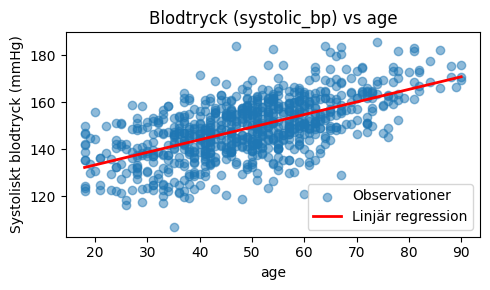


PCA - Förklarad variansandel: [0.4091, 0.2604]
PCA -Laddningar (komponenter):
               PC1    PC2
age          0.573 -0.280
weight       0.247  0.657
height       0.098  0.694
systolic_bp  0.569 -0.059
cholesterol  0.526 -0.069


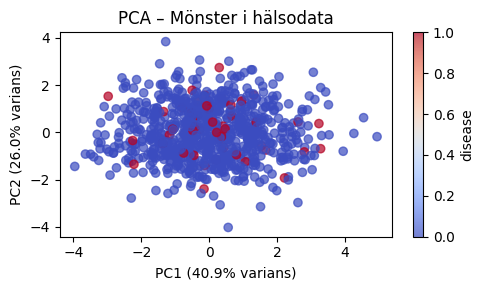

In [10]:
# Matris och vektoranalys (numpy)
vec_res = vector_matrix_bp_summary(df)
print("Vektor- och matrisanalys:")
for k, v in vec_res.items():
    print(f"  {k}: {v:.4f}")

# Linjär regression (systolic_bp från age och weight)
model, coef_df, r2 = fit_bp_linear_regression(df, features=["age", "weight"])
print(f"\nLinjär regression - Intercept: {model.intercept_:.2f} | R²: {r2:.4f}")
print(coef_df.to_string(index=False))

# Enkel linjär regression 
plot_bp_regression(df, feature="age")

# PCA 
loadings, scores, exp_var = run_pca_analysis(df, n_components=2)
print("\nPCA - Förklarad variansandel:", [round(float(x), 4) for x in exp_var])
print("PCA -Laddningar (komponenter):")
print(loadings.round(3))

plot_pca_scatter(df, scores, exp_var, color_col="disease")

I den här cellen beräknar jag andelen sjuka per kön och ritar en graf för en bredare överblick. Det gör jag för att se om sjukdom är vanligare hos kvinnor eller män och för att lättare upptäcka samband i datan.

Sjukdomsförekomst per kön:
sex  antal_individer  antal_sjuka  andel_sjuka  andel_procent  chi2_p_varde
  F              403           18     0.044665            4.5        0.1196
  M              397           29     0.073048            7.3        0.1196


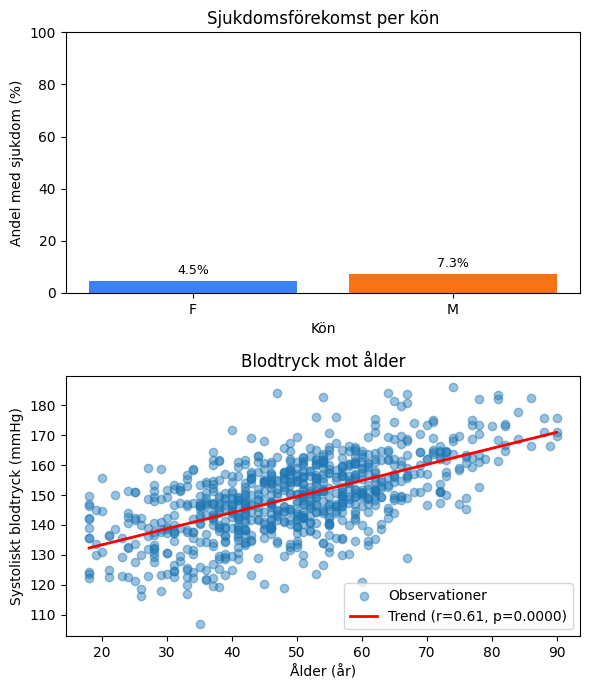

In [11]:
prev_table = disease_prevalence_by_sex(df)
print("Sjukdomsförekomst per kön:")
print(prev_table.to_string(index=False))

plot_extended_analysis(df)